BANK LOAN DATASET
   Age  Income  Loan_Amount  Credit_History Employment Property_Area  \
0   25   25000       100000               1        Yes         Urban   
1   30   40000       150000               1        Yes         Rural   
2   35   50000       200000               1        Yes         Urban   
3   40   60000       250000               1        Yes     Semiurban   
4   45   75000       300000               1        Yes         Urban   
5   28   30000       120000               0         No         Rural   
6   32   45000       180000               1        Yes     Semiurban   
7   50   90000       350000               1        Yes         Urban   
8   42   70000       280000               1        Yes     Semiurban   
9   29   28000       110000               0         No         Rural   

  Loan_Status  
0    Approved  
1    Approved  
2    Approved  
3    Approved  
4    Approved  
5    Rejected  
6    Approved  
7    Approved  
8    Approved  
9    Rejected  

Dataset Info

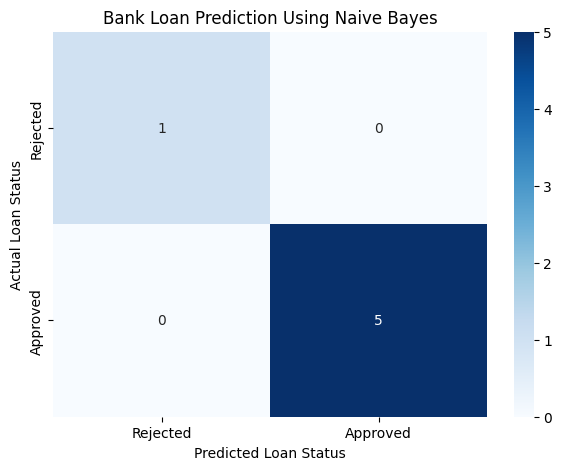


NEW APPLICANT DETAILS
   Age  Income  Loan_Amount  Credit_History  Employment  Property_Area
0   30   50000       150000               1           1              2

Loan Status: APPROVED


In [9]:

# BANK LOAN PREDICTION USING NAIVE BAYES CLASSIFICATION

# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Step 2: Create a sample bank loan dataset
data = pd.DataFrame({
    'Age': [25, 30, 35, 40, 45, 28, 32, 50, 42, 29,
            36, 48, 27, 38, 55, 31, 44, 26, 39, 52,
            33, 41, 24, 46, 34, 49, 37, 28, 43, 51],

    'Income': [25000, 40000, 50000, 60000, 75000, 30000,
               45000, 90000, 70000, 28000, 55000, 85000,
               22000, 65000, 95000, 42000, 72000, 26000,
               58000, 88000, 48000, 68000, 20000, 80000,
               52000, 92000, 62000, 32000, 76000, 98000],

    'Loan_Amount': [100000, 150000, 200000, 250000, 300000,
                    120000, 180000, 350000, 280000, 110000,
                    220000, 320000, 90000, 240000, 400000,
                    160000, 290000, 100000, 230000, 380000,
                    190000, 260000, 80000, 310000, 210000,
                    360000, 250000, 130000, 300000, 420000],

    'Credit_History': [1, 1, 1, 1, 1, 0, 1, 1, 1, 0,
                       1, 1, 0, 1, 1, 1, 1, 0, 1, 1,
                       1, 1, 0, 1, 1, 1, 1, 0, 1, 1],

    'Employment': ['Yes', 'Yes', 'Yes', 'Yes', 'Yes',
                   'No', 'Yes', 'Yes', 'Yes', 'No',
                   'Yes', 'Yes', 'No', 'Yes', 'Yes',
                   'Yes', 'Yes', 'No', 'Yes', 'Yes',
                   'Yes', 'Yes', 'No', 'Yes', 'Yes',
                   'Yes', 'Yes', 'No', 'Yes', 'Yes'],

    'Property_Area': ['Urban', 'Rural', 'Urban', 'Semiurban',
                      'Urban', 'Rural', 'Semiurban', 'Urban',
                      'Semiurban', 'Rural', 'Urban', 'Semiurban',
                      'Rural', 'Urban', 'Semiurban', 'Urban',
                      'Semiurban', 'Rural', 'Urban', 'Semiurban',
                      'Urban', 'Semiurban', 'Rural', 'Urban',
                      'Semiurban', 'Urban', 'Semiurban', 'Rural',
                      'Urban', 'Semiurban'],

    'Loan_Status': ['Approved', 'Approved', 'Approved', 'Approved',
                    'Approved', 'Rejected', 'Approved', 'Approved',
                    'Approved', 'Rejected', 'Approved', 'Approved',
                    'Rejected', 'Approved', 'Approved', 'Approved',
                    'Approved', 'Rejected', 'Approved', 'Approved',
                    'Approved', 'Approved', 'Rejected', 'Approved',
                    'Approved', 'Approved', 'Approved', 'Rejected',
                    'Approved', 'Approved']
})

# Step 3: Display the dataset
print("BANK LOAN DATASET")
print(data.head(10))

print("\nDataset Information:")
print(data.info())

# Step 4: Convert categorical data into numerical values
data['Employment'] = data['Employment'].map({
    'No': 0,
    'Yes': 1
})

data['Property_Area'] = data['Property_Area'].map({
    'Rural': 0,
    'Semiurban': 1,
    'Urban': 2
})

data['Loan_Status'] = data['Loan_Status'].map({
    'Rejected': 0,
    'Approved': 1
})

print("\nEncoded Dataset:")
print(data.head())

# Step 5: Separate input and output variables
X = data.drop('Loan_Status', axis=1)
y = data['Loan_Status']

# Step 6: Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)

# Step 7: Create Gaussian Naive Bayes classifier
model = GaussianNB()

# Step 8: Train the model
model.fit(X_train, y_train)

print("\nNaive Bayes Model Training Completed!")

# Step 9: Predict loan status
y_pred = model.predict(X_test)

print("\nPredicted Loan Status:")
print(y_pred)

print("\nActual Loan Status:")
print(y_test.values)

# Step 10: Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy: {:.2f}%".format(
    accuracy * 100
))

# Step 11: Display classification report
print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred,
    target_names=['Rejected', 'Approved'],
    zero_division=0
))

# Step 12: Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nCONFUSION MATRIX")
print(cm)

# Step 13: Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Rejected', 'Approved'],
    yticklabels=['Rejected', 'Approved']
)

plt.xlabel("Predicted Loan Status")
plt.ylabel("Actual Loan Status")
plt.title("Bank Loan Prediction Using Naive Bayes")

plt.show()

# Step 14: Predict loan status for a new applicant
new_applicant = pd.DataFrame([{
    'Age': 30,
    'Income': 50000,
    'Loan_Amount': 150000,
    'Credit_History': 1,
    'Employment': 1,
    'Property_Area': 2
}])

prediction = model.predict(new_applicant)

print("\nNEW APPLICANT DETAILS")
print(new_applicant)

if prediction[0] == 1:
    print("\nLoan Status: APPROVED")
else:
    print("\nLoan Status: REJECTED")
